In [1]:
import os, json, random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


## 1. Create a small instruction dataset
Each row contains an instruction, input, and expected response. This notebook includes a larger starter dataset and an explicit <|end|> token so generation knows when to stop. The dataset is still small, so treat this as a learning experiment.

In [2]:
examples = [
("Answer briefly", "What is AI?", "AI enables computers to perform tasks that usually require human intelligence."),
("Explain in detail", "What is AI?", "Artificial intelligence is a field of computing that builds systems able to perform tasks such as language understanding, image recognition, prediction, and planning. AI systems may use rules or learn patterns from data. Their quality depends on their data, design, and evaluation."),
("Answer briefly", "What is machine learning?", "Machine learning is a type of AI that learns patterns from data."),
("Explain in detail", "What is machine learning?", "Machine learning is a branch of AI where a model learns patterns from examples. During training, its parameters are adjusted to reduce a loss function. The model should then be evaluated on unseen data."),
("Answer briefly", "What is a Transformer?", "A Transformer is a neural network architecture that uses attention to process sequences."),
("Explain in detail", "What is a Transformer?", "A Transformer processes token sequences using attention. Its blocks commonly contain attention, feed-forward layers, residual connections, and normalization. A decoder-only Transformer uses causal masking to predict the next token without seeing future tokens."),
("Explain simply", "What is an embedding?", "An embedding turns a token into a list of numbers that a model can work with."),
("Answer briefly", "What is an epoch?", "An epoch is one complete pass through the training dataset."),
("Answer briefly", "What is overfitting?", "Overfitting happens when a model fits training examples too closely and performs poorly on new data."),
("Explain in detail", "What is overfitting?", "Overfitting occurs when a model learns training-specific details instead of general patterns. Training loss can be low while validation performance is poor. More representative data, regularization, dropout, and early stopping can help."),
("Answer briefly", "What is RAG?", "RAG retrieves relevant information and provides it to a language model as context."),
("Answer briefly", "What is a tokenizer?", "A tokenizer converts text into tokens or token IDs."),
("Answer briefly", "What is text generation?", "Text generation is producing text, often one token at a time."),
("Explain simply", "What is attention?", "Attention helps a model focus on useful tokens when processing a sequence."),
("Answer briefly", "What is inference?", "Inference is using a trained model to make predictions or generate outputs."),
("Summarize", "A Transformer uses attention to process tokens. It also contains feed-forward layers. Decoder-only models use causal masking to predict the next token.", "Transformers use attention and feed-forward layers; decoder-only models use causal masking for next-token prediction."),
("Summarize", "Machine learning models learn patterns from data. They are trained by optimizing a loss function. Their performance should be checked on unseen data.", "Machine learning models learn patterns from data and should be evaluated on unseen examples."),
("Give 3 examples", "Name applications of AI.", "1. Speech recognition. 2. Image classification. 3. Recommendation systems."),
("Give 3 examples", "Name common NLP tasks.", "1. Translation. 2. Summarization. 3. Question answering."),
("Give steps", "How do I train a model?", "1. Prepare and split the dataset. 2. Train on the training data. 3. Evaluate on held-out data."),
("Compare briefly", "Training loss and validation loss", "Training loss measures errors on training examples. Validation loss measures errors on separate examples and helps reveal poor generalization."),
("Answer in one sentence", "Why is a tokenizer needed?", "A tokenizer converts text into token IDs that a neural network can process."),
("Explain simply", "What is a chatbot?", "A chatbot is an application that interacts with users through messages and provides responses."),
("Explain in detail", "How can one model handle different tasks?", "A model can learn from varied instruction-response examples. The instruction describes the desired behavior and the input supplies the subject. During training, the model learns to predict the target response tokens. It can still fail on tasks that are not represented well in training."),
("Write Python code", "Reverse a string.", "text = 'hello'\nprint(text[::-1])"),
("Write Python code", "Check if a number is even.", "number = 8\nif number % 2 == 0:\n    print('Even')\nelse:\n    print('Odd')"),
("Translate into Tamil", "How are you?", "நீங்கள் எப்படி இருக்கிறீர்கள்?"),
("Translate into Tamil", "Thank you.", "நன்றி."),
("Translate into Tamil", "Good morning.", "காலை வணக்கம்."),
("Answer briefly", "What is an optimizer?", "An optimizer updates model parameters to reduce the training loss."),
("Explain simply", "What is a loss function?", "A loss function measures how far a prediction is from the expected answer."),
("Explain in detail", "What is supervised fine-tuning?", "Supervised fine-tuning trains a model on examples containing inputs and desired outputs. For instruction tuning, the examples cover different requests and response styles. The model learns to predict the target response tokens, and performance should be checked on examples not used for training.")
]

# Additional examples improve coverage of the instructions and concepts.
extra_examples = [('Answer briefly', 'What is deep learning?', 'Deep learning uses neural networks with many layers to learn patterns from data.'), ('Explain simply', 'What is deep learning?', 'Deep learning teaches a neural network to find patterns in examples.'), ('Answer briefly', 'What is NLP?', 'Natural language processing helps computers work with human language.'), ('Explain simply', 'What is NLP?', 'NLP helps computers process text and speech.'), ('Answer briefly', 'What is a neural network?', 'A neural network is a model made of connected layers that learn patterns.'), ('Answer briefly', 'What is an embedding?', 'An embedding represents a token as a list of numbers.'), ('Answer briefly', 'What is a token?', 'A token is a piece of text processed by a model.'), ('Answer briefly', 'What is a tokenizer?', 'A tokenizer splits text into tokens and maps them to IDs.'), ('Answer briefly', 'What is a vocabulary?', 'A vocabulary is the set of tokens a tokenizer knows.'), ('Answer briefly', 'What is a parameter?', 'A parameter is a learned value inside a model.'), ('Answer briefly', 'What is a hyperparameter?', 'A hyperparameter is a setting chosen for training, such as learning rate.'), ('Answer briefly', 'What is a loss function?', 'A loss function measures how different a prediction is from the target.'), ('Answer briefly', 'What is an optimizer?', 'An optimizer updates model parameters to reduce loss.'), ('Answer briefly', 'What is backpropagation?', 'Backpropagation computes gradients used to update model parameters.'), ('Answer briefly', 'What is an epoch?', 'An epoch is one complete pass through the training dataset.'), ('Answer briefly', 'What is a batch?', 'A batch is a group of examples processed together during training.'), ('Answer briefly', 'What is inference?', 'Inference is using a trained model to produce an output.'), ('Answer briefly', 'What is overfitting?', 'Overfitting happens when a model fits training data but performs poorly on new data.'), ('Answer briefly', 'What is validation data?', 'Validation data helps evaluate a model during development.'), ('Answer briefly', 'What is test data?', 'Test data measures performance on held-out examples after training.'), ('Answer briefly', 'What is RAG?', 'RAG retrieves relevant documents and gives them to a model as context.'), ('Answer briefly', 'What is BM25?', 'BM25 ranks documents by how well their words match a search query.'), ('Answer briefly', 'What is chunking?', 'Chunking divides a document into smaller pieces for retrieval.'), ('Answer briefly', 'What is cosine similarity?', 'Cosine similarity compares vectors using the angle between them.'), ('Answer briefly', 'What is text summarization?', 'Text summarization creates a shorter version that keeps the main points.'), ('Answer briefly', 'What is question answering?', 'Question answering produces an answer using a question and relevant information.'), ('Answer briefly', 'What is text generation?', 'Text generation creates text by predicting tokens one after another.'), ('Answer briefly', 'What is temperature in generation?', 'Temperature controls how random token sampling is.'), ('Answer briefly', 'What is top-k sampling?', 'Top-k sampling chooses the next token from the k most likely tokens.'), ('Answer briefly', 'What is top-p sampling?', 'Top-p sampling chooses from tokens within a cumulative probability threshold.'), ('Answer briefly', 'What is supervised fine-tuning?', 'Supervised fine-tuning trains a model on examples of inputs and desired outputs.'), ('Answer briefly', 'What is a causal mask?', 'A causal mask prevents a token from attending to future tokens.'), ('Answer briefly', 'What is self-attention?', 'Self-attention lets each token use information from other allowed tokens.'), ('Answer briefly', 'What is a Transformer?', 'A Transformer uses attention and feed-forward layers to process token sequences.'), ('Explain simply', 'What is a causal mask?', 'It stops the model from looking ahead at future words.'), ('Explain simply', 'What is a loss function?', 'It gives the model a score for how wrong its prediction is.'), ('Explain simply', 'What is an epoch?', 'One epoch means the model has gone through all training examples once.'), ('Explain simply', 'What is a tokenizer?', 'It breaks text into smaller pieces the model can read.'), ('Give 3 examples', 'Name three uses of AI.', '1. Speech recognition. 2. Medical image analysis. 3. Product recommendations.'), ('Give 3 examples', 'Name three NLP tasks.', '1. Translation. 2. Summarization. 3. Question answering.'), ('Give steps', 'How does model training work?', '1. Prepare examples. 2. Predict outputs and calculate loss. 3. Update parameters. 4. Evaluate the model.'), ('Summarize', 'A tokenizer splits text into tokens. Each token is mapped to an ID. The model processes those IDs and predicts output tokens.', 'A tokenizer converts text into IDs that a model can process.'), ('Summarize', 'RAG searches external documents and adds relevant text to the prompt. A language model then generates an answer using that context.', 'RAG retrieves relevant text and uses it to ground a generated answer.'), ('Translate into Tamil', 'Good morning.', 'காலை வணக்கம்.'), ('Translate into Tamil', 'Thank you for your help.', 'உங்கள் உதவிக்கு நன்றி.'), ('Translate into Tamil', 'How are you?', 'நீங்கள் எப்படி இருக்கிறீர்கள்?'), ('Write Python code', 'Print numbers from 1 to 5.', 'for number in range(1, 6):\n    print(number)'), ('Write Python code', 'Check whether a number is positive.', "number = 5\nif number > 0:\n    print('Positive')\nelse:\n    print('Not positive')"), ('Answer in one sentence', 'Why do we need validation data?', 'Validation data helps check whether a model generalizes beyond its training examples.'), ('Compare briefly', 'Text generation and summarization', 'Text generation creates a continuation or new text, while summarization produces a shorter version of existing content.'), ('Explain simply', 'What is a chatbot?', 'A chatbot is a program that talks with people through messages.'), ('Explain in detail', 'Why can a small language model produce nonsense?', 'A small model has limited capacity and may see too few examples. A small vocabulary and weak tokenization can also hurt generation. Training loss alone does not prove that the model follows instructions. More representative data and evaluation are needed.')]
examples.extend(extra_examples)

df = pd.DataFrame(examples, columns=["instruction", "input", "response"])
print("Examples:", len(df))
display(df.head())

Examples: 84


,instruction,input,response
0,Answer briefly,What is AI?,AI enables computers to perform tasks that usu...
1,Explain in detail,What is AI?,Artificial intelligence is a field of computin...
2,Answer briefly,What is machine learning?,Machine learning is a type of AI that learns p...
3,Explain in detail,What is machine learning?,Machine learning is a branch of AI where a mod...
4,Answer briefly,What is a Transformer?,A Transformer is a neural network architecture...


## 2. Format prompts

Training format:

```text
User: <instruction>
Input: <input>
Assistant: <response>
```

The loss will be applied to assistant response tokens, not the prompt tokens.

In [3]:
def make_prompt(instruction, input_text):
    # Tokenizer splits on spaces; keep prompt fields consistently space-separated.
    clean_instruction = " ".join(str(instruction).split())
    clean_input = " ".join(str(input_text).split())
    return f"User: {clean_instruction} Input: {clean_input} Assistant:"

def make_full_text(instruction, input_text, response):
    clean_response = " ".join(str(response).split())
    return make_prompt(instruction, input_text) + " " + clean_response + " <|end|>"

df["prompt"] = [make_prompt(i, x) for i, x in zip(df.instruction, df.input)]
df["full_text"] = [make_full_text(i, x, r) for i, x, r in zip(df.instruction, df.input, df.response)]
print(df.loc[0, "full_text"])

User: Answer briefly Input: What is AI? Assistant: AI enables computers to perform tasks that usually require human intelligence. <|end|>


## 3. Tokenize the tiny corpus

This demo intentionally trains on all supplied examples and repeats them to help the small model memorize the fixed test prompts. The monitoring set is the same original corpus, so its metrics are **not** independent validation metrics and do not show generalization.


In [4]:
# This is a tiny teaching dataset. To make the demo learn the supplied examples,
# train on ALL examples and repeat them. This intentionally measures memorization,
# not generalization to unseen examples.
df = pd.DataFrame(examples, columns=["instruction", "input", "response"])

def make_prompt(instruction, input_text):
    clean_instruction = " ".join(str(instruction).split())
    clean_input = " ".join(str(input_text).split())
    return f"User: {clean_instruction} Input: {clean_input} Assistant:"

def make_full_text(instruction, input_text, response):
    clean_response = " ".join(str(response).split())
    return make_prompt(instruction, input_text) + " " + clean_response + " <|end|>"

df["prompt"] = [make_prompt(i, x) for i, x in zip(df["instruction"], df["input"])]
df["full_text"] = [
    make_full_text(i, x, r)
    for i, x, r in zip(df["instruction"], df["input"], df["response"])
]

# Repeat the small dataset to provide more optimizer updates per epoch.
# Every original example remains in training so the demo's fixed test prompts
# can be learned. val_df is the same set and is NOT an independent validation set.
REPEAT_FACTOR = 6
train_df = pd.concat([df] * REPEAT_FACTOR, ignore_index=True)
val_df = df.copy()

# Fit vocabulary to the complete small teaching corpus.
tokenizer = Tokenizer(filters="", lower=False, oov_token="[UNK]")
tokenizer.fit_on_texts(df["full_text"].tolist())
word_index = tokenizer.word_index
vocab_size = len(word_index) + 1
MAX_LEN = 128

print("Unique examples:", len(df))
print("Training rows (repeated):", len(train_df), "Monitoring rows:", len(val_df))
print("Vocabulary size:", vocab_size)
print("Sample prompt:", repr(df.iloc[0]["prompt"]))
print("Sample full text:", repr(df.iloc[0]["full_text"]))
print("Sample token IDs:", tokenizer.texts_to_sequences([df.iloc[0]["full_text"]])[0][:15])
assert len(word_index) > 1, "Tokenizer vocabulary is empty. Run the dataset cell first."
assert df["prompt"].map(lambda v: isinstance(v, str)).all()
assert df["full_text"].map(lambda v: isinstance(v, str)).all()


Unique examples: 84
Training rows (repeated): 504 Monitoring rows: 84
Vocabulary size: 566
Sample prompt: 'User: Answer briefly Input: What is AI? Assistant:'
Sample full text: 'User: Answer briefly Input: What is AI? Assistant: AI enables computers to perform tasks that usually require human intelligence. <|end|>'
Sample token IDs: [2, 9, 10, 3, 8, 6, 143, 4, 70, 263, 97, 14, 144, 98, 20]


## 4. Build next-token targets

The input and target are shifted by one token. `sample_weight` is 1 for response tokens (including <|end|>) and 0 for prompt/padding tokens.

In [5]:
def encode_row(prompt, full_text):
    if not isinstance(prompt, str) or not isinstance(full_text, str):
        return None

    prompt_ids = tokenizer.texts_to_sequences([prompt])[0]
    full_ids = tokenizer.texts_to_sequences([full_text])[0]

    full_ids = full_ids[:MAX_LEN]
    if len(full_ids) < 2:
        return None

    # Mask prompt tokens. Loss is calculated only on the response and <|end|>.
    prompt_len = min(len(prompt_ids), len(full_ids))
    x = full_ids[:-1]
    y = full_ids[1:]
    weights = [
        1.0 if (j + 1) >= prompt_len else 0.0
        for j in range(len(y))
    ]
    return x, y, weights


def make_arrays(frame):
    xs, ys, ws = [], [], []
    skipped = 0

    for row in frame.itertuples(index=False):
        item = encode_row(row.prompt, row.full_text)
        if item is None:
            skipped += 1
            continue
        x, y, w = item
        xs.append(x)
        ys.append(y)
        ws.append(w)

    if not xs:
        raise ValueError(
            "No valid examples were encoded. Run the dataset, prompt/tokenizer, "
            "and this cell in order. Check the printed sample token IDs above."
        )

    X = pad_sequences(xs, maxlen=MAX_LEN - 1, padding="post",
                      truncating="post", dtype="int32")
    Y = pad_sequences(ys, maxlen=MAX_LEN - 1, padding="post",
                      truncating="post", dtype="int32")
    W = pad_sequences(ws, maxlen=MAX_LEN - 1, padding="post",
                      truncating="post", dtype="float32", value=0.0)
    W = W * (Y != 0)

    # Every example must have at least one response token included in the loss.
    valid_rows = W.sum(axis=1) > 0
    X, Y, W = X[valid_rows], Y[valid_rows], W[valid_rows]

    if len(X) == 0:
        raise ValueError(
            "Examples were tokenized, but no response tokens were selected for loss. "
            "Check prompt/full_text construction."
        )

    print(f"Encoded {len(X)} examples; skipped {skipped}; "
          f"response tokens: {int(W.sum())}")

    return X.astype("int32"), Y.astype("int32"), W.astype("float32")


X_train, Y_train, W_train = make_arrays(train_df)
X_val, Y_val, W_val = make_arrays(val_df)

print("Train shapes:", X_train.shape, Y_train.shape, W_train.shape)
print("Validation shapes:", X_val.shape, Y_val.shape, W_val.shape)
print("Response tokens in first example:", int(W_train[0].sum()))


Encoded 504 examples; skipped 0; response tokens: 6942
Encoded 84 examples; skipped 0; response tokens: 1157
Train shapes: (504, 127) (504, 127) (504, 127)
Validation shapes: (84, 127) (84, 127) (84, 127)
Response tokens in first example: 12


## 5. Build a decoder-only Transformer

In [6]:
D_MODEL = 96
NUM_HEADS = 4
FF_DIM = 192
NUM_LAYERS = 2
DROPOUT = 0.1

class DecoderBlock(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, ff_dim, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.attn = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=d_model // num_heads, dropout=dropout
        )
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(ff_dim, activation="gelu"),
            tf.keras.layers.Dense(d_model)
        ])
        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-5)
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-5)
        self.drop1 = tf.keras.layers.Dropout(dropout)
        self.drop2 = tf.keras.layers.Dropout(dropout)

    def call(self, x, training=False):
        a = self.attn(query=x, value=x, key=x, use_causal_mask=True, training=training)
        x = self.norm1(x + self.drop1(a, training=training))
        f = self.ffn(x, training=training)
        return self.norm2(x + self.drop2(f, training=training))

class MiniInstructionLLM(tf.keras.Model):
    def __init__(self, vocab_size, max_len, d_model=96, num_heads=4, ff_dim=192, num_layers=2, dropout=0.1):
        super().__init__()
        self.token_embedding = tf.keras.layers.Embedding(vocab_size, d_model)
        self.position_embedding = tf.keras.layers.Embedding(max_len, d_model)
        self.blocks = [DecoderBlock(d_model, num_heads, ff_dim, dropout) for _ in range(num_layers)]
        self.norm = tf.keras.layers.LayerNormalization(epsilon=1e-5)
        self.output_layer = tf.keras.layers.Dense(vocab_size)
        self.max_len = max_len

    def call(self, token_ids, training=False):
        length = tf.shape(token_ids)[1]
        positions = tf.range(length)
        x = self.token_embedding(token_ids) + self.position_embedding(positions)
        for block in self.blocks:
            x = block(x, training=training)
        return self.output_layer(self.norm(x))

model = MiniInstructionLLM(vocab_size, MAX_LEN-1, D_MODEL, NUM_HEADS, FF_DIM, NUM_LAYERS, DROPOUT)
_ = model(tf.zeros((1, MAX_LEN-1), dtype=tf.int32))
model.summary()

Model: "mini_instruction_llm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (1, 127, 96)           │        54,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (127, 96)              │        12,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block (DecoderBlock)    │ ?                      │        74,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block_1 (DecoderBlock)  │ ?                      │        74,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_4           │ (1, 127, 96)           │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (1, 127, 566)          │        54,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 271,190 (1.03 MB)

 Trainable params: 271,190 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Train with response-only loss

The loss is applied to assistant response tokens and the end marker. This training setup is designed to demonstrate memorization of a tiny dataset, not to produce a general-purpose chatbot.


In [7]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    weighted_metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="token_accuracy")]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5)
]

# Because val_df contains the same original examples, val_loss here monitors
# whether the model has learned the tiny demo corpus; it does not measure generalization.
history = model.fit(
    X_train, Y_train, sample_weight=W_train,
    validation_data=(X_val, Y_val, W_val),
    batch_size=8, epochs=250, callbacks=callbacks, shuffle=True
)


Epoch 1/250
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.6379 - token_accuracy: 0.0671 - val_loss: 0.5755 - val_token_accuracy: 0.1184 - learning_rate: 2.0000e-04
Epoch 2/250
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.5390 - token_accuracy: 0.1697 - val_loss: 0.4763 - val_token_accuracy: 0.2584 - learning_rate: 2.0000e-04
Epoch 3/250
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.4462 - token_accuracy: 0.3369 - val_loss: 0.3818 - val_token_accuracy: 0.4624 - learning_rate: 2.0000e-04
Epoch 4/250
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.3629 - token_accuracy: 0.5307 - val_loss: 0.3034 - val_token_accuracy: 0.6344 - learning_rate: 2.0000e-04
Epoch 5/250
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.2950 - token_accuracy: 0.6664 - val_loss: 0.2409 - val_token_accuracy: 0.7606 - learning_rate: 2.0000e-04
Epoch 6/250
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.2394 - token_accuracy: 0.7576 - val_loss: 0.1906 - val_token_accuracy: 0.8297 - learning_rate: 2.0

## 7. Plot training curves

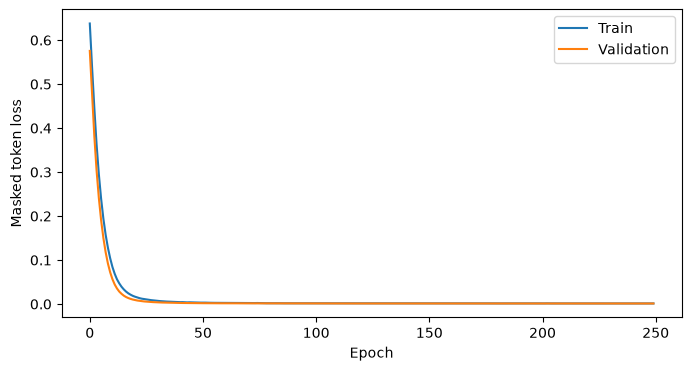

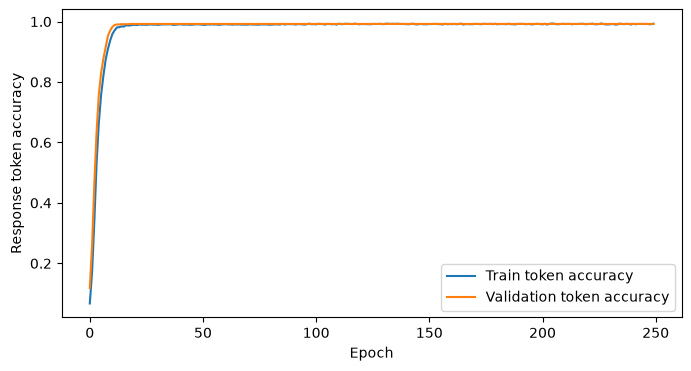

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Masked token loss"); plt.legend(); plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["token_accuracy"], label="Train token accuracy")
if "val_token_accuracy" in history.history:
    plt.plot(history.history["val_token_accuracy"], label="Validation token accuracy")
plt.xlabel("Epoch"); plt.ylabel("Response token accuracy"); plt.legend(); plt.show()

## 8. Generate a response token by token

In [9]:
def generate_response(instruction, input_text, max_new_tokens=60, temperature=0.0):
    prompt = make_prompt(instruction, input_text)
    prompt_ids = tokenizer.texts_to_sequences([prompt])[0]
    if not prompt_ids:
        return ""

    generated = list(prompt_ids)
    end_id = tokenizer.word_index.get("<|end|>")

    for _ in range(max_new_tokens):
        # Keep the most recent context, and right-pad exactly as in training.
        context = generated[-(MAX_LEN - 1):]
        x = pad_sequences(
            [context],
            maxlen=MAX_LEN - 1,
            padding="post",
            truncating="pre",
            value=0
        ).astype("int32")

        # Predict the next token from the final real context position.
        logits = model(x, training=False)[0, len(context) - 1, :]

        # Do not generate padding; stop cleanly at the explicit response marker.
        logits = tf.tensor_scatter_nd_update(
            logits,
            [[0]],
            [tf.cast(-1e9, logits.dtype)]
        )

        if temperature <= 0:
            next_id = int(tf.argmax(logits).numpy())
        else:
            scaled_logits = logits / max(float(temperature), 1e-5)
            next_id = int(
                tf.random.categorical(scaled_logits[None, :], 1)[0, 0].numpy()
            )

        if next_id == 0 or next_id == end_id:
            break

        generated.append(next_id)

    new_ids = generated[len(prompt_ids):]
    words = tokenizer.sequences_to_texts([new_ids])[0].strip()
    return words.replace("<|end|>", "").strip()


## 9. Test multiple instruction types

These test prompts overlap with the training examples intentionally. Check whether the model can reproduce the provided examples. Do not interpret this as proof of generalization to new questions.


In [14]:
tests = [
    ("Answer briefly", "What is AI?"),
    ("Explain in detail", "What is AI?"),
    ("Explain simply", "What is attention?"),
    ("Translate into Tamil","How are you?"),
    ("Write Python code", "Reverse a string."),
    ("Write Python code", "Check if a number is even."),
    ("Answer briefly","What is the difference between AI and machine learning?")
]

for instruction, input_text in tests:
    print("Instruction:", instruction)
    print("Input:", input_text)
    print("Assistant:", generate_response(instruction, input_text))
    print("-" * 50)

Instruction: Answer briefly
Input: What is AI?
Assistant: AI enables computers to perform tasks that usually require human intelligence.
--------------------------------------------------
Instruction: Explain in detail
Input: What is AI?
Assistant: Artificial intelligence is a field of computing that builds systems able to perform tasks such as language understanding, image recognition, prediction, and planning. AI systems may use rules or learn patterns from data. Their quality depends on their data, design, and evaluation.
--------------------------------------------------
Instruction: Explain simply
Input: What is attention?
Assistant: Attention helps a model focus on useful tokens when processing a sequence.
--------------------------------------------------
Instruction: Translate into Tamil
Input: How are you?
Assistant: நீங்கள் எப்படி இருக்கிறீர்கள்?
--------------------------------------------------
Instruction: Write Python code
Input: Reverse a string.
Assistant: text = 'hello

## 10. Interactive mini assistant

In [11]:
print("Mini Instruction-Following LLM. Type 'exit' to stop.")
# while True:
#     instruction = input("\nInstruction (e.g. Answer briefly / Explain in detail): ").strip()
#     if instruction.lower() in {"exit", "quit"}:
#         print("Stopped.")
#         break
#     input_text = input("Input/topic: ").strip()
#     if not input_text:
#         continue
#     print("Assistant:", generate_response(instruction, input_text, temperature=0.7))

Mini Instruction-Following LLM. Type 'exit' to stop.


## 11. Save model and project files

In [12]:
SAVE_DIR = "mini_instruction_llm"
os.makedirs(SAVE_DIR, exist_ok=True)
model.save_weights(os.path.join(SAVE_DIR, "model.weights.h5"))
with open(os.path.join(SAVE_DIR, "tokenizer.json"), "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())
with open(os.path.join(SAVE_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump({
        "max_len": MAX_LEN, "vocab_size": voca|b_size, "d_model": D_MODEL,
        "num_heads": NUM_HEADS, "ff_dim": FF_DIM, "num_layers": NUM_LAYERS,
        "dropout": DROPOUT
    }, f, indent=2)
df.to_csv(os.path.join(SAVE_DIR, "instruction_dataset.csv"), index=False, encoding="utf-8")
print("Saved to:", SAVE_DIR)

NameError: name 'voca' is not defined

## What you learned

1. **Instruction formatting:** same model, different user instructions.
2. **Supervised fine-tuning:** learn from instruction → expected response pairs.
3. **Response-only loss:** the prompt provides context; the assistant response is the target.
4. **Causal self-attention:** predict the next token without looking at future tokens.
5. **Autoregressive generation:** append each predicted token and repeat.

**Limitations:** This tiny model will not behave like ChatGPT. The whitespace tokenizer is basic, Tamil tokenization is especially limited, and the dataset remains small. The explicit end token prevents unbounded generation, but does not guarantee correct answers. The next improvement is a larger clean dataset and a subword tokenizer, followed later by fine-tuning a pretrained model.